## Low-order FIR approximation of the split-step propagation kernel

This notebook designs a low-order real-coefficient FIR for the propagation step
`exp(1j * phi_R) -> psi` using PyDynamic's `LSFIR` implementation.

The cutoff frequency is set manually in `config["fit_band_hz"]`. The FIR is fit
uniformly over `[0, +fit_band_hz]`, which makes the design independent of one
specific `phi_R` realization. The negative-frequency response is then determined
by the real-filter conjugate symmetry, so the `phi_R` realization is used only for
field validation.

In [ ]:
from pathlib import Path
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal
from scipy.fft import fft, ifft
from scipy.io import loadmat
from PyDynamic.model_estimation.fit_filter import LSFIR


project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_file = project_root / "data" / "interim" / "refractive_phase_psd.mat"
output_dir = project_root / "outputs" / "propagation_lsfir"
output_dir.mkdir(parents=True, exist_ok=True)

config = {
    "run_matlab": True,
    "matlab_cmd": os.environ.get("MATLAB_CMD", "matlab"),
    "output_file": output_file,
    "output_dir": output_dir,
    "rhof_veff_ratio": 2.0,
    "U": 2.0,
    "p1": 2.2,
    "p2": 3.8,
    "mu0": 1.0,
    "sim_time": 300.0,
    "t_samp": 0.02,
    "seed": 123,
    "fir_order": 1024,
    "fit_band_hz": 0.02,
    "fit_grid_size": 4096,
    "field_comparison_orders": [128, 256, 512, 768, 1024],
}


def q(value):
    return "'" + str(value).replace("'", "''") + "'"


if config["run_matlab"]:
    matlab_code = f"""
addpath({q(project_root / 'tools' / 'cpssm_utils')});
get_refractive_phase_psd( ...
    'output_file', {q(config['output_file'])}, ...
    'rhof_veff_ratio', {config['rhof_veff_ratio']}, ...
    'U', {config['U']}, ...
    'p1', {config['p1']}, ...
    'p2', {config['p2']}, ...
    'mu0', {config['mu0']}, ...
    'sim_time', {config['sim_time']}, ...
    't_samp', {config['t_samp']}, ...
    'seed', {config['seed']});
"""
    subprocess.run([config["matlab_cmd"], "-batch", matlab_code], cwd=project_root, check=True)

mat = loadmat(config["output_file"], squeeze_me=True)
frequency_hz = np.ravel(mat["frequency_hz"]).astype(float)
mu = np.ravel(mat["mu"]).astype(float)
phi_R = np.ravel(mat["phi_R"]).astype(float)
Fs = float(np.asarray(mat["sample_rate_hz"]).squeeze())
dt = float(np.asarray(mat["sample_interval_s"]).squeeze())
rho_over_v = float(np.asarray(mat["rhof_veff_ratio"]).squeeze())
N_fft = int(np.asarray(mat["nfft"]).squeeze())

f_fft = np.fft.fftfreq(N_fft, d=dt)
omega_fft = 2 * np.pi * f_fft / Fs
omega_pos = 2 * np.pi * frequency_hz / Fs
H_full = np.exp(-0.5j * (2 * np.pi * f_fft * rho_over_v) ** 2)
H_pos = np.exp(-0.5j * mu**2)
u = np.exp(1j * phi_R)
U = fft(u)

max_group_delay = (Fs * rho_over_v) ** 2 * (2 * np.pi * frequency_hz[-1] / Fs)
print(f"N_fft = {N_fft}")
print(f"Fs = {Fs:.6e} Hz, dt = {dt:.6e} s")
print(f"rho_F / v_eff = {rho_over_v:.6e} s")
fit_band_group_delay = 2 * np.pi * Fs * rho_over_v**2 * config["fit_band_hz"]
print(f"fir_order = {config['fir_order']} ({config['fir_order'] + 1} taps)")
print(f"fit_band_hz = {config['fit_band_hz']:.6e} Hz")
print(f"group delay at fit cutoff = {fit_band_group_delay:.1f} samples")
print(f"suggested centered order for cutoff = {int(np.ceil(2 * fit_band_group_delay))}")
print(f"full-band max group delay = {max_group_delay:.1f} samples")

> In path (line 109)
In addpath (line 96) 
N_fft = 15360
Fs = 5.000000e+01 Hz, dt = 2.000000e-02 s
rho_F / v_eff = 2.000000e+00 s
fir_order = 1024 (1025 taps)
fit_band_hz = 1.000000e+01 Hz
group delay at fit cutoff = 12566.4 samples
suggested centered order for cutoff = 25133
full-band max group delay = 31411.8 samples


In [16]:
fit_band_hz = float(config["fit_band_hz"])
if not 0 < fit_band_hz < Fs / 2:
    raise ValueError(f"fit_band_hz must be between 0 and Nyquist ({Fs / 2:.3f} Hz).")

f_fit = np.linspace(0.0, fit_band_hz, int(config["fit_grid_size"]))
omega_fit = 2 * np.pi * f_fit / Fs
H_fit = np.exp(-0.5j * (2 * np.pi * f_fit * rho_over_v) ** 2)

band_summary = {
    "fit_band_hz": fit_band_hz,
    "fit_frequency_range": "[0, fit_band_hz]",
    "fit_grid_size": len(f_fit),
    "group_delay_at_cutoff_samples": float(2 * np.pi * Fs * rho_over_v**2 * fit_band_hz),
    "suggested_centered_order": int(np.ceil(2 * 2 * np.pi * Fs * rho_over_v**2 * fit_band_hz)),
}
pd.DataFrame([band_summary]).to_csv(output_dir / "fixed_band_design_summary.csv", index=False)
band_summary

{'fit_band_hz': 10.0,
 'fit_frequency_range': '[0, fit_band_hz]',
 'fit_grid_size': 4096,
 'group_delay_at_cutoff_samples': 12566.370614359173,
 'suggested_centered_order': 25133}

In [17]:
def fit_fixed_band_fir(order: int):
    tau = order // 2
    lags = np.arange(order + 1)
    H_fit_ri = np.hstack((np.real(H_fit), np.imag(H_fit)))
    b_fir, _ = LSFIR(H_fit_ri, order, f_fit, Fs, tau, verbose=False, inv=False)
    return np.asarray(b_fir), tau, lags


def response_metrics(H_target, H_est):
    phase_error = np.angle(H_est * np.conj(H_target))
    mag_error = np.abs(H_est) - np.abs(H_target)
    return {
        "mag_rmse": float(np.sqrt(np.mean(mag_error**2))),
        "phase_rmse_rad": float(np.sqrt(np.mean(phase_error**2))),
        "complex_rel_error": float(np.linalg.norm(H_est - H_target) / np.linalg.norm(H_target)),
    }


b_fir, tau, lags = fit_fixed_band_fir(config["fir_order"])
H_fir_pos = (np.exp(-1j * np.outer(omega_pos, lags)) @ b_fir) * np.exp(-1j * omega_pos * tau)
fit_band = frequency_hz <= fit_band_hz

band_metrics = response_metrics(H_pos[fit_band], H_fir_pos[fit_band])
full_metrics = response_metrics(H_pos, H_fir_pos)
metrics = {
    **{f"fit_band_{k}": v for k, v in band_metrics.items()},
    **{f"full_band_{k}": v for k, v in full_metrics.items()},
    "fit_band_hz": fit_band_hz,
    "fir_order": config["fir_order"],
    "num_taps": len(b_fir),
    "tau": tau,
    "rho_over_v": rho_over_v,
    "lsfir_function": "PyDynamic.model_estimation.fit_filter.LSFIR",
}
pd.DataFrame([metrics]).to_csv(output_dir / "metrics.csv", index=False)
metrics

{'fit_band_mag_rmse': 0.9249871173217474,
 'fit_band_phase_rmse_rad': 1.734371241988165,
 'fit_band_complex_rel_error': 0.9568556501741513,
 'full_band_mag_rmse': 2613318032.7700586,
 'full_band_phase_rmse_rad': 1.7889985473294974,
 'full_band_complex_rel_error': 2613318033.3831563,
 'fit_band_hz': 10.0,
 'fir_order': 1024,
 'num_taps': 1025,
 'tau': 512,
 'rho_over_v': 2.0,
 'lsfir_function': 'PyDynamic.model_estimation.fit_filter.LSFIR'}

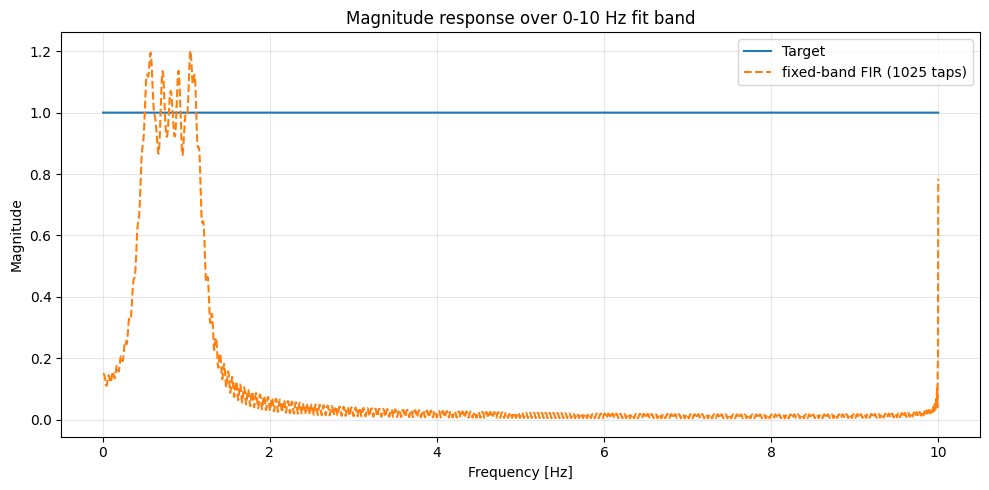

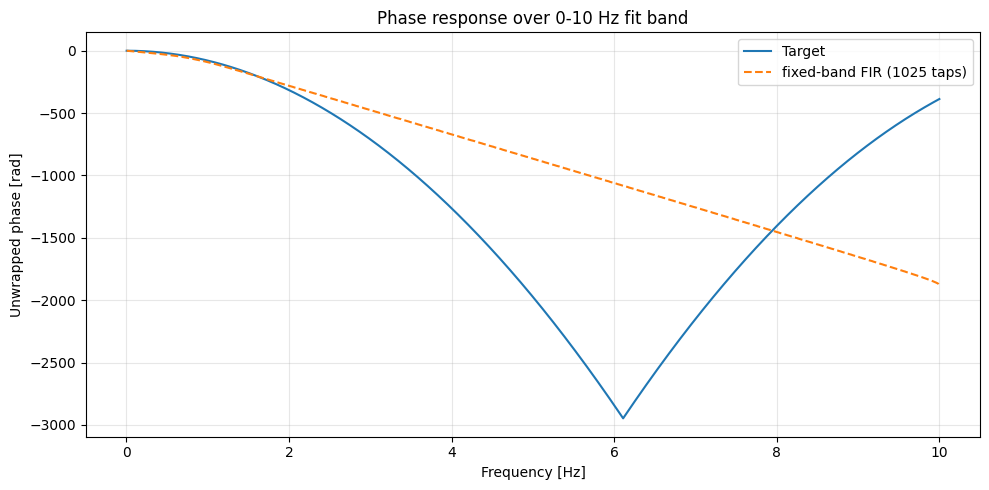

In [18]:
label = f"fixed-band FIR ({len(b_fir)} taps)"

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(frequency_hz[fit_band], np.abs(H_pos[fit_band]), label="Target")
ax.plot(frequency_hz[fit_band], np.abs(H_fir_pos[fit_band]), "--", label=label)
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Magnitude")
ax.set_title(f"Magnitude response over 0-{fit_band_hz:g} Hz fit band")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "frequency_magnitude_fit_band.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(frequency_hz[fit_band], np.unwrap(np.angle(H_pos[fit_band])), label="Target")
ax.plot(frequency_hz[fit_band], np.unwrap(np.angle(H_fir_pos[fit_band])), "--", label=label)
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Unwrapped phase [rad]")
ax.set_title(f"Phase response over 0-{fit_band_hz:g} Hz fit band")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "frequency_phase_fit_band.png", dpi=300)
plt.show()

In [19]:
psi_target = ifft(fft(u) * H_full)
psi_fir_raw = signal.lfilter(b_fir, [1.0], u)
psi_fir = np.roll(psi_fir_raw, tau)
edge = len(b_fir) + tau
sl = slice(edge, -edge) if 2 * edge < N_fft else slice(None)

field_metrics = {
    "field_rel_error": float(np.linalg.norm(psi_fir[sl] - psi_target[sl]) / np.linalg.norm(psi_target[sl])),
    "amp_rmse": float(np.sqrt(np.mean((np.abs(psi_fir[sl]) - np.abs(psi_target[sl])) ** 2))),
    "phase_rmse_rad": float(
        np.sqrt(np.mean(np.angle(psi_fir[sl] * np.conj(psi_target[sl])) ** 2))
    ),
    "edge_samples_removed": edge,
}
pd.DataFrame([field_metrics]).to_csv(output_dir / "field_validation_metrics.csv", index=False)
field_metrics

{'field_rel_error': 2771922.7723263344,
 'amp_rmse': 2787984.8214657125,
 'phase_rmse_rad': 1.8110213204232848,
 'edge_samples_removed': 1537}

,fir_order,num_taps,tau,field_rel_error,amp_rmse,phase_rmse_rad,edge_samples_removed
0,128,129,64,1.042644e+06,1.041624e+06,1.756599,193
1,256,257,128,3.689225e+05,3.685956e+05,1.823608,385
2,512,513,256,1.877051e+06,1.880719e+06,1.819015,769
3,768,769,384,1.487392e+06,1.486994e+06,1.810006,1153
4,1024,1025,512,2.771923e+06,2.787985e+06,1.811021,1537


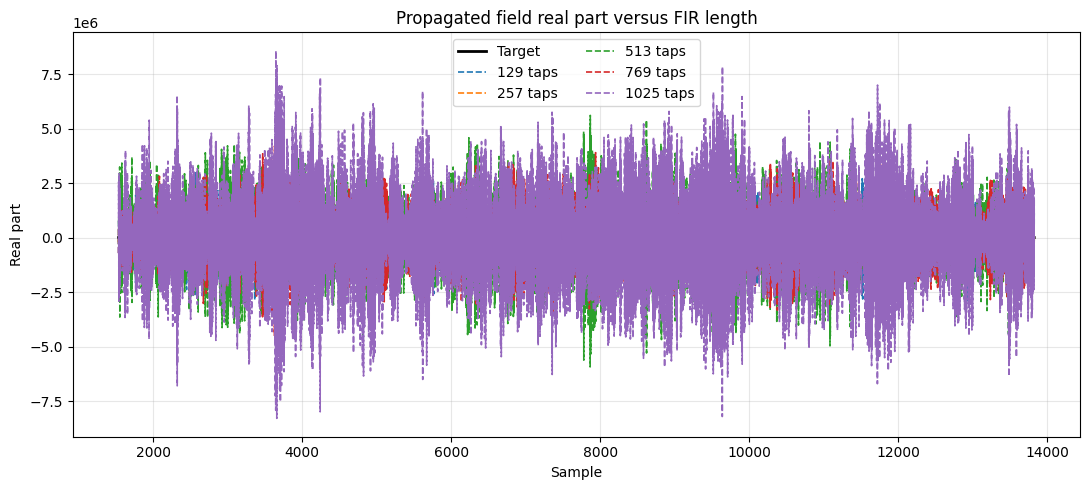

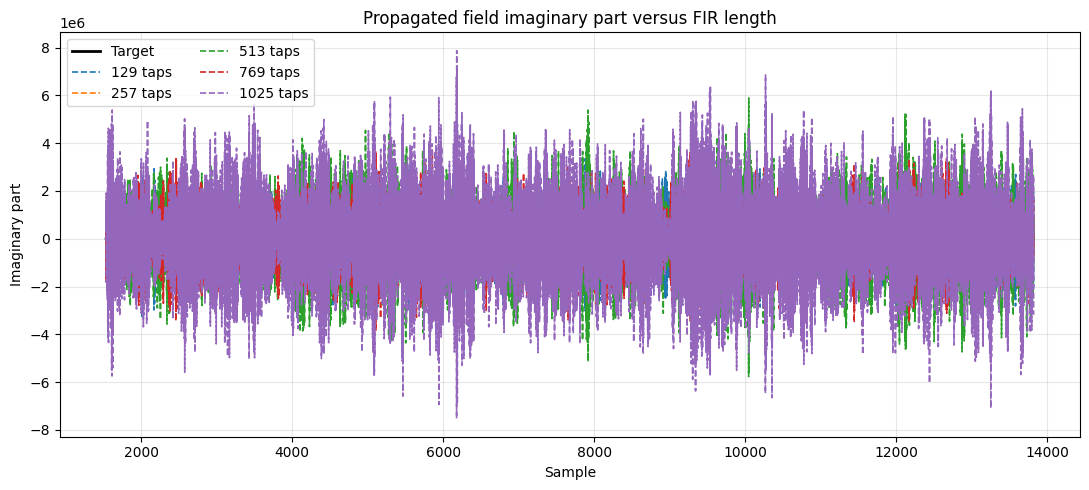

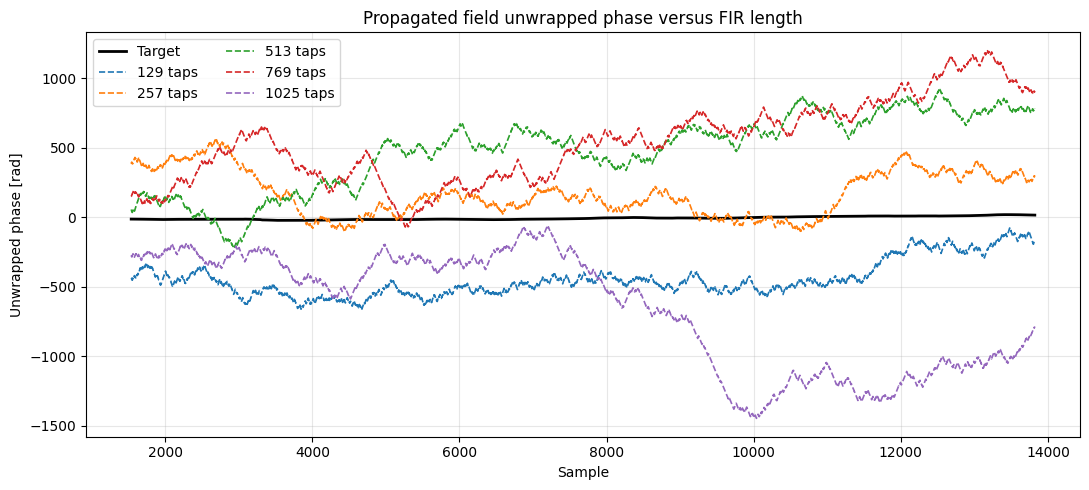

In [20]:
comparison_orders = sorted(set(order for order in config["field_comparison_orders"] if order <= N_fft - 1))
comparison_rows = []
comparison_series = []

for order in comparison_orders:
    b_i, tau_i, _ = fit_fixed_band_fir(order)
    psi_i = np.roll(signal.lfilter(b_i, [1.0], u), tau_i)
    edge_i = len(b_i) + tau_i
    sl_i = slice(edge_i, -edge_i) if 2 * edge_i < N_fft else slice(None)
    comparison_rows.append(
        {
            "fir_order": order,
            "num_taps": len(b_i),
            "tau": tau_i,
            "field_rel_error": float(
                np.linalg.norm(psi_i[sl_i] - psi_target[sl_i]) / np.linalg.norm(psi_target[sl_i])
            ),
            "amp_rmse": float(np.sqrt(np.mean((np.abs(psi_i[sl_i]) - np.abs(psi_target[sl_i])) ** 2))),
            "phase_rmse_rad": float(
                np.sqrt(np.mean(np.angle(psi_i[sl_i] * np.conj(psi_target[sl_i])) ** 2))
            ),
            "edge_samples_removed": edge_i,
        }
    )
    comparison_series.append({"num_taps": len(b_i), "psi": psi_i, "edge": edge_i})

field_comparison_df = pd.DataFrame(comparison_rows)
field_comparison_df.to_csv(output_dir / "field_tap_comparison_metrics.csv", index=False)
display(field_comparison_df)

max_edge = max(item["edge"] for item in comparison_series)
if 2 * max_edge >= N_fft:
    max_edge = 0
plot_slice = slice(max_edge, N_fft - max_edge)
sample_axis = np.arange(max_edge, N_fft - max_edge)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sample_axis, np.real(psi_target[plot_slice]), color="black", linewidth=2, label="Target")
for item in comparison_series:
    ax.plot(sample_axis, np.real(item["psi"][plot_slice]), "--", linewidth=1.2, label=f"{item['num_taps']} taps")
ax.set_xlabel("Sample")
ax.set_ylabel("Real part")
ax.set_title("Propagated field real part versus FIR length")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(output_dir / "field_real_tap_comparison.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sample_axis, np.imag(psi_target[plot_slice]), color="black", linewidth=2, label="Target")
for item in comparison_series:
    ax.plot(sample_axis, np.imag(item["psi"][plot_slice]), "--", linewidth=1.2, label=f"{item['num_taps']} taps")
ax.set_xlabel("Sample")
ax.set_ylabel("Imaginary part")
ax.set_title("Propagated field imaginary part versus FIR length")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(output_dir / "field_imag_tap_comparison.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sample_axis, np.unwrap(np.angle(psi_target))[plot_slice], color="black", linewidth=2, label="Target")
for item in comparison_series:
    ax.plot(sample_axis, np.unwrap(np.angle(item["psi"]))[plot_slice], "--", linewidth=1.2, label=f"{item['num_taps']} taps")
ax.set_xlabel("Sample")
ax.set_ylabel("Unwrapped phase [rad]")
ax.set_title("Propagated field unwrapped phase versus FIR length")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(output_dir / "field_unwrapped_phase_tap_comparison.png", dpi=300)
plt.show()

In [21]:
coeff_df = pd.DataFrame(
    {
        "lag_causal": np.arange(len(b_fir)),
        "lag_after_delay": lags + tau,
        "b_real": np.real(b_fir),
        "b_imag": np.imag(b_fir),
    }
)
coeff_df.to_csv(output_dir / "propagation_fir_coefficients.csv", index=False)
np.savez(
    output_dir / "propagation_fir_coefficients.npz",
    b_fir=b_fir,
    tau=tau,
    fir_order=config["fir_order"],
    dt=dt,
    Fs=Fs,
    rho_over_v=rho_over_v,
    N_fft=N_fft,
    fit_band_hz=fit_band_hz,
    fit_grid_size=config["fit_grid_size"],
    lsfir_function="PyDynamic.model_estimation.fit_filter.LSFIR",
)
coeff_df.head()

,lag_causal,lag_after_delay,b_real,b_imag
0,0,512,5.733216e+04,0.0
1,1,513,-8.721906e+05,0.0
2,2,514,6.372074e+06,0.0
3,3,515,-2.943900e+07,0.0
4,4,516,9.519954e+07,0.0
